In [1]:
import sys

In [2]:
import os,time
import xarray as xr
import glob

import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from eofs.xarray import Eof
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import GPy

In [3]:
SECONDS_PER_DAY = 86400
output_dir = "gp_results"
os.makedirs(output_dir, exist_ok=True)

In [4]:
# loading code
train_exps = ["historical", "ssp126", "ssp370", "ssp585", "hist-GHG", "hist-aer"]

train_out = {e: xr.open_dataset(f"data/outputs_{e}.nc") for e in train_exps}
train_in  = {e: xr.open_dataset(f"data/inputs_{e}.nc")  for e in train_exps}
# `train_out` is a dictionary of xarray Datasets (one per experiment).
# An xarray Dataset is like a bundle of labeled grids: here, each variable
# (tas, pr, ...) has axes of time x member x latitude x longitude.

# one singular experiment: ssp245
ssp245_out = xr.open_dataset("data/outputs_ssp245.nc")
ssp245_in  = xr.open_dataset("data/inputs_ssp245.nc")

In [5]:
train_in

{'historical': <xarray.Dataset> Size: 37MB
 Dimensions:    (time: 165, latitude: 96, longitude: 144)
 Coordinates:
   * time       (time) int64 1kB 1850 1851 1852 1853 1854 ... 2011 2012 2013 2014
   * latitude   (latitude) float64 768B -90.0 -88.11 -86.21 ... 86.21 88.11 90.0
   * longitude  (longitude) float64 1kB 0.0 2.5 5.0 7.5 ... 352.5 355.0 357.5
 Data variables:
     CO2        (time) float64 1kB ...
     SO2        (time, latitude, longitude) float64 18MB ...
     CH4        (time) float64 1kB ...
     BC         (time, latitude, longitude) float64 18MB ...,
 'ssp126': <xarray.Dataset> Size: 19MB
 Dimensions:    (time: 86, latitude: 96, longitude: 144)
 Coordinates:
   * time       (time) int64 688B 2015 2016 2017 2018 ... 2097 2098 2099 2100
   * latitude   (latitude) float64 768B -90.0 -88.11 -86.21 ... 86.21 88.11 90.0
   * longitude  (longitude) float64 1kB 0.0 2.5 5.0 7.5 ... 352.5 355.0 357.5
 Data variables:
     CO2        (time) float64 688B ...
     SO2        (time,

In [6]:
train_out

{'historical': <xarray.Dataset> Size: 137MB
 Dimensions:                    (member: 3, time: 165, lat: 96, lon: 144)
 Coordinates:
   * member                     (member) int64 24B 1 2 3
   * time                       (time) int64 1kB 1850 1851 1852 ... 2013 2014
   * lat                        (lat) float64 768B -90.0 -88.11 ... 88.11 90.0
   * lon                        (lon) float64 1kB 0.0 2.5 5.0 ... 355.0 357.5
     quantile                   float64 8B ...
 Data variables:
     diurnal_temperature_range  (member, time, lat, lon) float32 27MB ...
     tas                        (member, time, lat, lon) float32 27MB ...
     pr                         (member, time, lat, lon) float32 27MB ...
     pr90                       (member, time, lat, lon) float64 55MB ...,
 'ssp126': <xarray.Dataset> Size: 24MB
 Dimensions:                    (member: 1, time: 86, lat: 96, lon: 144)
 Coordinates:
   * member                     (member) int64 8B 1
   * time                       (time

In [7]:
# ── concat into single training X, Y (order matches train_exps) ─────────
X = xr.concat([train_in[e] for e in train_exps], dim='time').compute()
Y = xr.concat([train_out[e].mean(dim="member") for e in train_exps], dim='time').compute()

Y['pr']   *= SECONDS_PER_DAY
Y['pr90'] *= SECONDS_PER_DAY

time_axis = np.arange(1, X.dims['time'] + 1)
X['time'] = time_axis
Y['time'] = time_axis

 /tmp/ipykernel_1847/3929042868.py:8: FutureWarning:The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


In [8]:
# normalization
max_co2, max_ch4 = 2400, 0.6
normalize_co2 = lambda d: d / max_co2
normalize_ch4 = lambda d: d / max_ch4

In [9]:
#metrics
def area_weighted_mean(da):
    w = np.cos(np.deg2rad(da.lat))
    return da.weighted(w).mean(['lat', 'lon'])

def climatebench_scores(truth, pred):
    """truth, pred: (time, lat, lon) over 2080-2100, same coords, physical units."""
    truth_tmean = truth.mean('time')
    pred_tmean  = pred.mean('time')
    denom = float(np.abs(area_weighted_mean(truth_tmean)))

    nrmse_spatial = float(np.sqrt(area_weighted_mean((pred_tmean - truth_tmean)**2))) / denom

    g_truth = area_weighted_mean(truth)
    g_pred  = area_weighted_mean(pred)
    nrmse_global = float(np.sqrt(((g_pred - g_truth)**2).mean('time'))) / denom

    nrmse_total = nrmse_spatial + 5 * nrmse_global
    return nrmse_spatial, nrmse_global, nrmse_total

In [10]:
print(X.dims)
print(X['SO2'].shape)
print(X['BC'].shape)

FrozenMappingWarningOnValuesAccess({'time': 753, 'latitude': 96, 'longitude': 144})
(753, 96, 144)
(753, 96, 144)


In [11]:
print("Fitting EOFs...")
so2_solver = Eof(X['SO2']); so2_pcs = so2_solver.pcs(npcs=5, pcscaling=1)
bc_solver  = Eof(X['BC']);  bc_pcs  = bc_solver.pcs(npcs=5, pcscaling=1)

Fitting EOFs...


In [12]:
# ── training feature matrix: CO2, CH4, BC0-4, SO2_0-4 ────────────────────
X_train = np.column_stack([
    normalize_co2(X['CO2'].data),
    normalize_ch4(X['CH4'].data),
    bc_pcs.values,
    so2_pcs.values,
])
X_mean, X_std = X_train.mean(0), X_train.std(0)
X_train_scaled = (X_train - X_mean) / X_std
print("X_train:", X_train.shape)

X_train: (753, 12)


In [13]:
# targets as full flattened fields
tgt_names = {"tas": "tas", "pr": "pr", "pr90": "pr90", "dtr": "diurnal_temperature_range"}
y_mean, y_std, Y_scaled = {}, {}, {}
for short, full in tgt_names.items():
    arr = Y[full].stack(space=["lat", "lon"]).values
    y_mean[short], y_std[short] = arr.mean(), arr.std()
    Y_scaled[short] = (arr - y_mean[short]) / y_std[short]

In [14]:
# fit one GP per target
gp_models = {}
for short in Y_scaled:
    print(f"Fitting GP for {short}... ({time.ctime()})")
    k_co2 = GPy.kern.Matern32(1, active_dims=[0], ARD=True)
    k_ch4 = GPy.kern.Matern32(1, active_dims=[1], ARD=True)
    k_bc  = GPy.kern.Matern32(5, active_dims=list(range(2, 7)), ARD=True)
    k_so2 = GPy.kern.Matern32(5, active_dims=list(range(7, 12)), ARD=True)
    kernel = k_co2 + k_ch4 + k_bc + k_so2

    m = GPy.models.GPRegression(X_train_scaled, Y_scaled[short], kernel)
    m.optimize(optimizer='lbfgsb', messages=True, max_iters=200)
    gp_models[short] = m
    print(f"  done, log-lik {m.log_likelihood():.1f}")

Fitting GP for tas... (Sun Oct 18 03:04:57 2026)


  done, log-lik -3322306.6
Fitting GP for pr... (Sun Oct 18 03:43:46 2026)


  done, log-lik -13878873.6
Fitting GP for pr90... (Sun Oct 18 04:22:12 2026)


  done, log-lik -13973782.6
Fitting GP for dtr... (Sun Oct 18 04:47:49 2026)


  done, log-lik -10344142.7


In [ ]:
# prepare ssp245 test inputs
n_test = ssp245_in.dims['time']

X_test = np.column_stack([
    normalize_co2(ssp245_in['CO2'].data),
    normalize_ch4(ssp245_in['CH4'].data),
    bc_solver.projectField(ssp245_in['BC'], neofs=5, eofscaling=1).values,
    so2_solver.projectField(ssp245_in['SO2'], neofs=5, eofscaling=1).values,
])
X_test_scaled = (X_test - X_mean) / X_std

truth = {
    "tas":  ssp245_out['tas'].mean('member'),
    "pr":   ssp245_out['pr'].mean('member') * SECONDS_PER_DAY,
    "pr90": ssp245_out['pr90'].mean('member') * SECONDS_PER_DAY,
    "dtr":  ssp245_out['diurnal_temperature_range'].mean('member'),
}


 /tmp/ipykernel_1847/3791446730.py:2: FutureWarning:The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


In [ ]:
# predict full field + predictive variance
pred, pred_var_ts = {}, {}
for short, m in gp_models.items():
    mean_s, var_s = m.predict(X_test_scaled)
    maps = (mean_s * y_std[short] + y_mean[short]).reshape(n_test, 96, 144)
    pred[short] = xr.DataArray(
        maps, dims=["time", "lat", "lon"],
        coords={"time": ssp245_out.time.values,
                "lat": ssp245_out.lat.values, "lon": ssp245_out.lon.values})
    v = var_s[:, 0] if var_s.ndim == 2 else var_s
    pred_var_ts[short] = v * y_std[short] ** 2

In [ ]:
# scores over 2090-2100 (last 21 years)
print("\n           Spatial   Global    Total")
scores = {}
for short in truth:
    t = truth[short].isel(time=slice(-21, None))
    p = pred[short].isel(time=slice(-21, None))
    s, g, tot = climatebench_scores(t, p)
    scores[short] = (s, g, tot)
    print(f"{short:5s}   {s:8.3f} {g:8.3f} {tot:8.3f}")



           Spatial   Global    Total
tas        0.089    0.039    0.284
pr         2.324    0.353    4.088
pr90       2.718    0.450    4.970
dtr        9.476    2.195   20.454


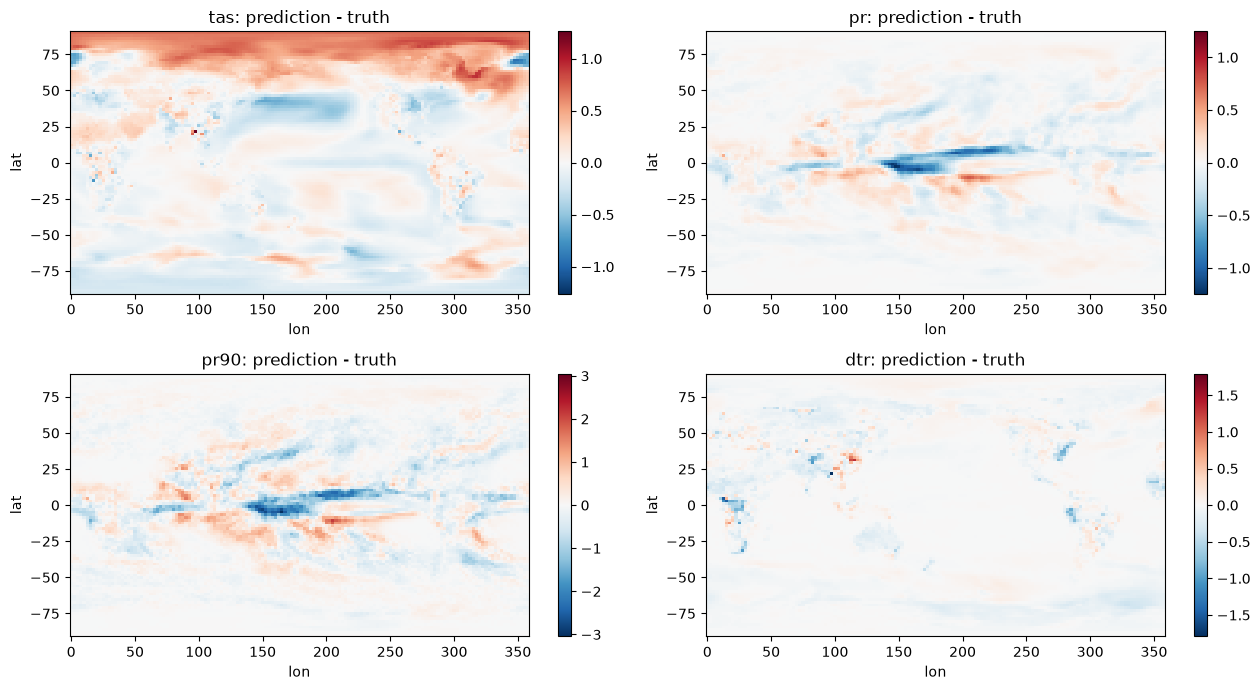

In [ ]:
# difference maps (prediction - truth), 2080-2100 time-mean
fig, axs = plt.subplots(2, 2, figsize=(13, 7))
for ax, short in zip(axs.ravel(), truth):
    t = truth[short].isel(time=slice(-21, None)).mean('time')
    p = pred[short].isel(time=slice(-21, None)).mean('time')
    (p - t).plot(ax=ax, cmap='RdBu_r', center=0)
    ax.set_title(f"{short}: prediction - truth")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "gp_diff_maps.png"), dpi=120)
plt.show()